# Scenario

ML algorithm for bike sharing demand prediction.

## Setup


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

RANDOM_STATE = 789

np.random.seed(RANDOM_STATE)
rng = np.random.default_rng(RANDOM_STATE)

# Load


In [67]:
data = pd.read_csv("..\\data\\sample\\SeoulBikeData.csv")
data_orig = data.copy()

## EDA (Exploratory Data Analysis)


In [68]:
data.head()

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


In [69]:
data.describe(include="all")

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
count,8760,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760,8760,8760
unique,365,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,2,2
top,01/12/2017,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Spring,No Holiday,Yes
freq,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2208,8328,8465
mean,NaN,704.602055,11.500000,12.882922,58.226256,1.724909,1436.825799,4.073813,0.569111,0.148687,0.075068,NaN,NaN,NaN
std,NaN,644.997468,6.922582,11.944825,20.362413,1.036300,608.298712,13.060369,0.868746,1.128193,0.436746,NaN,NaN,NaN
min,NaN,0.000000,0.000000,-17.800000,0.000000,0.000000,27.000000,-30.600000,0.000000,0.000000,0.000000,NaN,NaN,NaN
25%,NaN,191.000000,5.750000,3.500000,42.000000,0.900000,940.000000,-4.700000,0.000000,0.000000,0.000000,NaN,NaN,NaN
50%,NaN,504.500000,11.500000,13.700000,57.000000,1.500000,1698.000000,5.100000,0.010000,0.000000,0.000000,NaN,NaN,NaN
75%,NaN,1065.250000,17.250000,22.500000,74.000000,2.300000,2000.000000,14.800000,0.930000,0.000000,0.000000,NaN,NaN,NaN


In [70]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Date                       8760 non-null   object 
 1   Rented Bike Count          8760 non-null   int64  
 2   Hour                       8760 non-null   int64  
 3   Temperature(°C)            8760 non-null   float64
 4   Humidity(%)                8760 non-null   int64  
 5   Wind speed (m/s)           8760 non-null   float64
 6   Visibility (10m)           8760 non-null   int64  
 7   Dew point temperature(°C)  8760 non-null   float64
 8   Solar Radiation (MJ/m2)    8760 non-null   float64
 9   Rainfall(mm)               8760 non-null   float64
 10  Snowfall (cm)              8760 non-null   float64
 11  Seasons                    8760 non-null   object 
 12  Holiday                    8760 non-null   object 
 13  Functioning Day            8760 non-null   objec

In [71]:
null_info = data.isnull().sum()
null_info[null_info > 0]

Series([], dtype: int64)

### Categorical and Numerical Features Mapping

Before further examination, add numerical (boolean) columns for some categorical features. Also, create bins for some numerical features.


In [72]:
holiday_map = {"Holiday": 1, "No Holiday": 0}
data["Is holiday"] = data["Holiday"].map(holiday_map)

functioning_day_map = {"Yes": 1, "No": 0}
data["Is functioning day"] = data["Functioning Day"].map(functioning_day_map)

data["Is Winter"] = data["Seasons"].apply(lambda x: 1 if x == "Winter" else 0)
data["Is Spring"] = data["Seasons"].apply(lambda x: 1 if x == "Spring" else 0)
data["Is Summer"] = data["Seasons"].apply(lambda x: 1 if x == "Summer" else 0)
data["Is Autumn"] = data["Seasons"].apply(lambda x: 1 if x == "Autumn" else 0)

data["Temp. Bin"] = pd.cut(
    data["Temperature(°C)"],
    bins=[-20, -10, 0, 10, 20, 30, 40],
    labels=["-20;-10", "-10;0", "0;10", "10;20", "20;30", "30;40"],
    include_lowest=True,
)

## Correlation


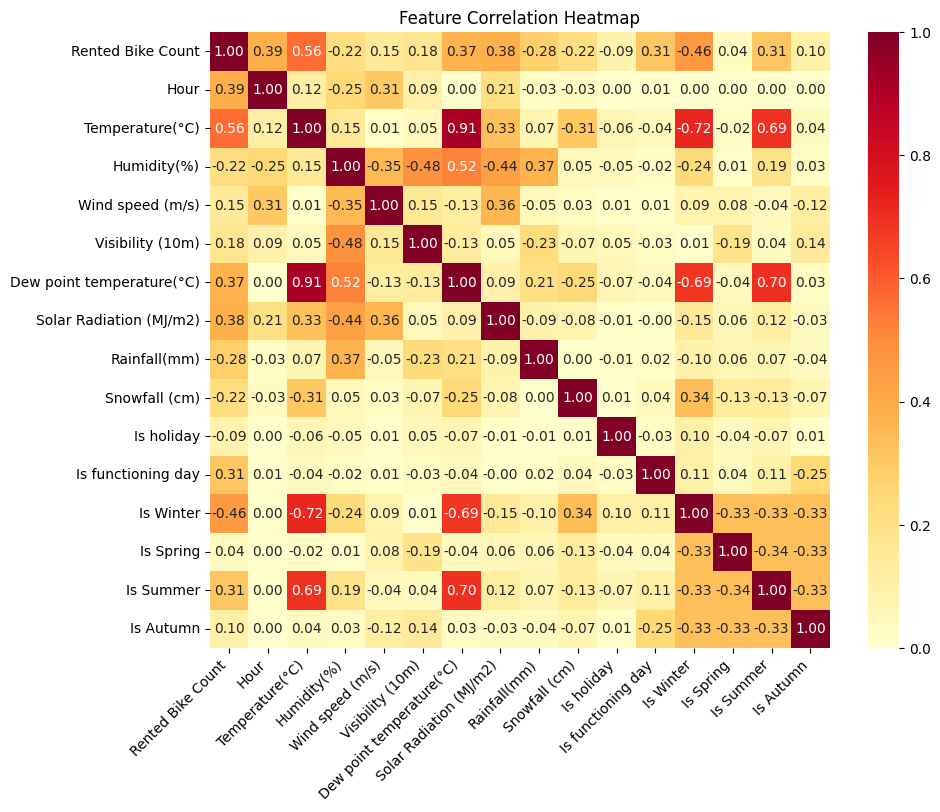

In [73]:
data_corr = data.corr(numeric_only=True, method="spearman")

# plot correlation heatmap
plt.figure(figsize=(10, 8))
axes = sns.heatmap(data_corr.abs(), annot=data_corr, cmap="YlOrRd", fmt=".2f")
axes.set_xticklabels(axes.get_xticklabels(), rotation=45, horizontalalignment="right")
axes.set_yticklabels(axes.get_yticklabels(), rotation=0, horizontalalignment="right")
plt.title("Feature Correlation Heatmap")
plt.show()

## Data distribution


Text(0.5, 0.98, 'Distributions')

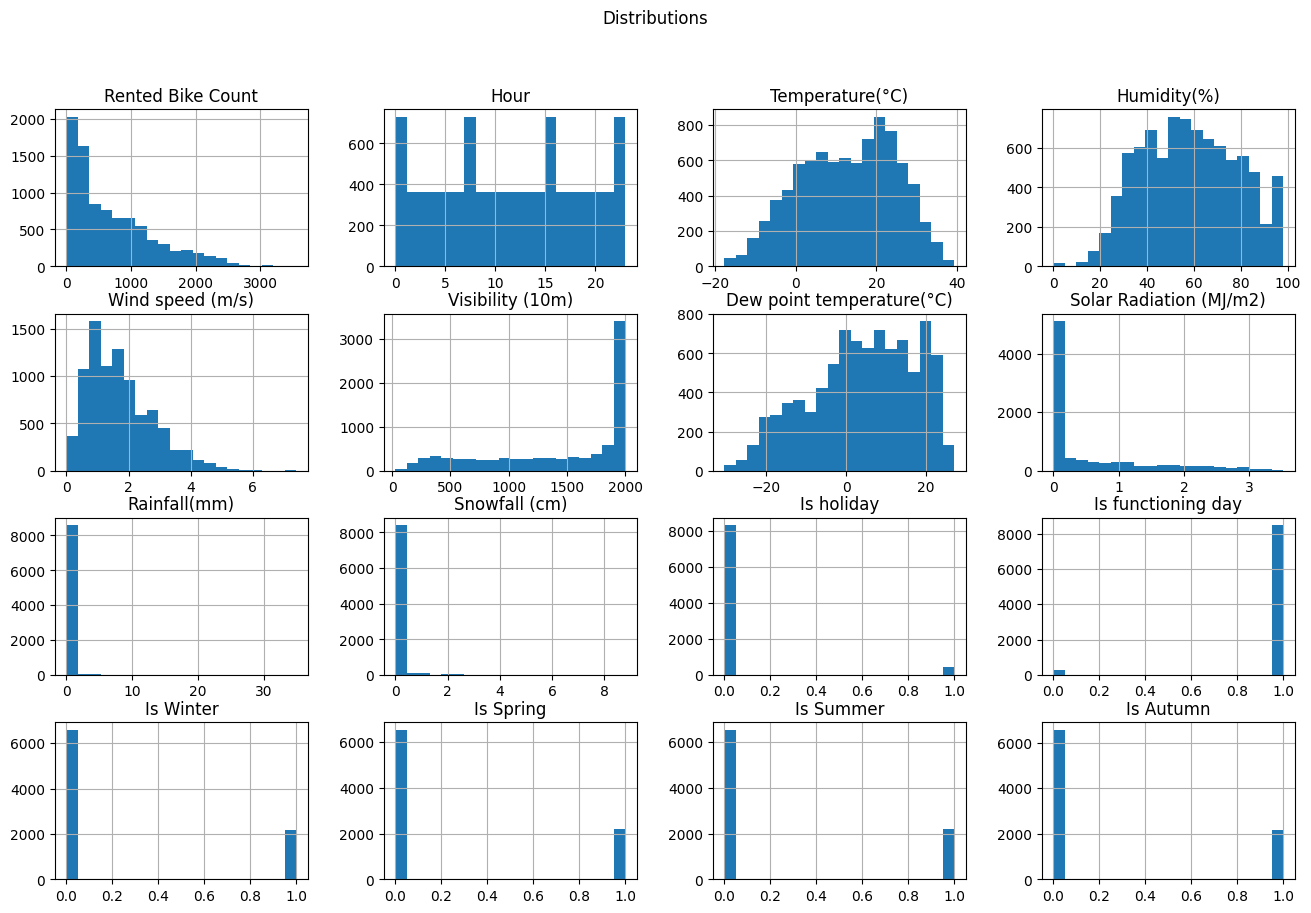

In [74]:
data.hist(bins=20, figsize=(16, 10))
plt.suptitle("Distributions")

Text(0.5, 1.0, 'Rented Bike Count per Temperature Bin')

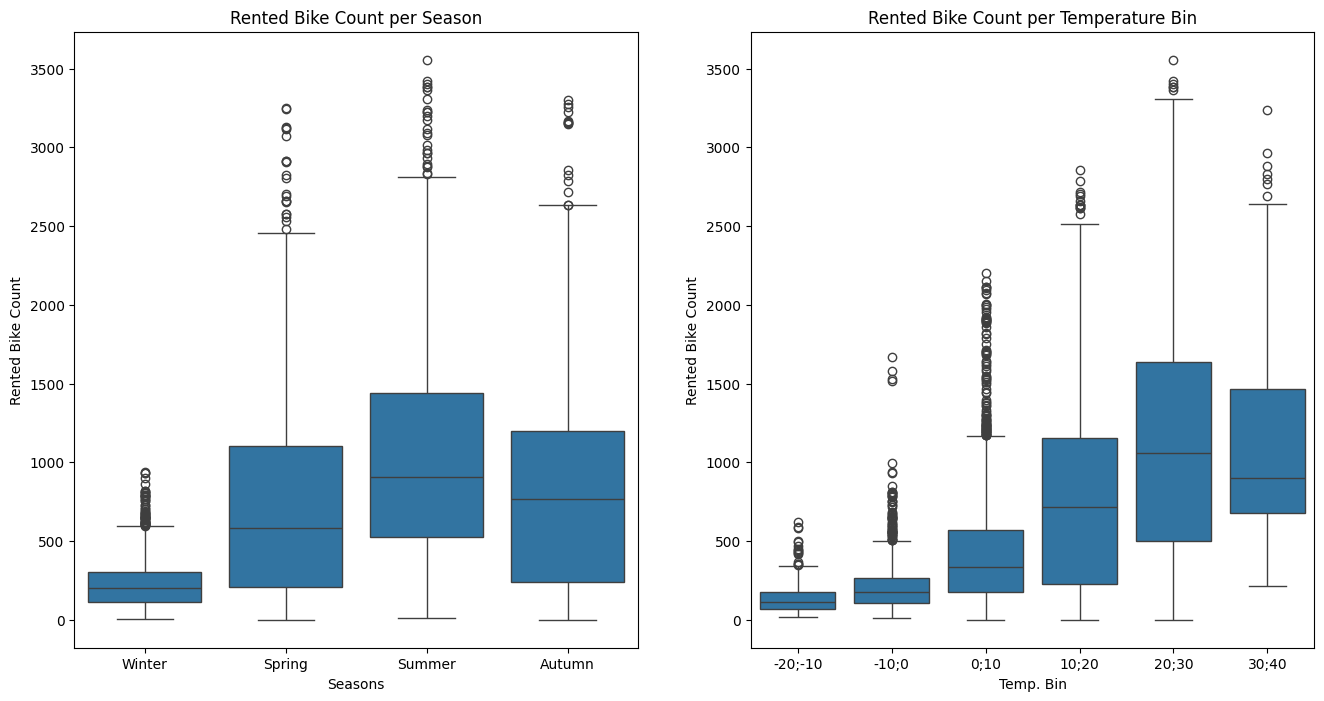

In [75]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

sns.boxplot(data=data, x="Seasons", y="Rented Bike Count", ax=axes[0])
axes[0].set_title("Rented Bike Count per Season")

sns.boxplot(data=data, x="Temp. Bin", y="Rented Bike Count", ax=axes[1])
axes[1].set_title("Rented Bike Count per Temperature Bin")